In [39]:
import kagglehub
path = kagglehub.dataset_download("ahmedmohamed2003/cafe-sales-dirty-data-for-cleaning-training")

Using Colab cache for faster access to the 'cafe-sales-dirty-data-for-cleaning-training' dataset.


In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
df=pd.read_csv(path + '/dirty_cafe_sales.csv')


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


In [43]:
df.isnull().sum()

,0
Transaction ID,0
Item,333
Quantity,138
Price Per Unit,179
Total Spent,173
Payment Method,2579
Location,3265
Transaction Date,159


In [44]:
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [45]:
df.describe()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_9226047,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


In [46]:
df.shape


(10000, 8)

In [47]:
(df.isnull().sum()/df.shape[0])*100

,0
Transaction ID,0.00
Item,3.33
Quantity,1.38
Price Per Unit,1.79
Total Spent,1.73
Payment Method,25.79
Location,32.65
Transaction Date,1.59


In [48]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


In [49]:
df.dropna(inplace=True)

In [50]:
import pandas as pd

# Safely load df if it's not defined in the current session
if 'df' not in globals():
    try:
        df = pd.read_csv(path + '/dirty_cafe_sales.csv')
        df.dropna(inplace=True)
    except NameError:
        import kagglehub
        path = kagglehub.dataset_download("ahmedmohamed2003/cafe-sales-dirty-data-for-cleaning-training")
        df = pd.read_csv(path + '/dirty_cafe_sales.csv')
        df.dropna(inplace=True)

# Correcting column types to 'object'
df['Item'] = df['Item'].astype('object')
df['Quantity'] = df['Quantity'].astype('object')
df['Price Per Unit'] = df['Price Per Unit'].astype('object')
df['Total Spent'] = df['Total Spent'].astype('object')

In [51]:
obj_cols=df.select_dtypes('object').columns.tolist()
obj_cols

['Transaction ID',
 'Item',
 'Quantity',
 'Price Per Unit',
 'Total Spent',
 'Payment Method',
 'Location',
 'Transaction Date']

In [52]:
import pandas as pd

# 1. Explicitly define which columns should be numeric and convert them
actual_num_cols = ['Quantity', 'Price Per Unit', 'Total Spent']
for col in actual_num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 2. Identify the remaining object/categorical columns
actual_obj_cols = [col for col in df.columns if col not in actual_num_cols]

# 3. Fill missing values with Mode for categorical columns
for col in actual_obj_cols:
    if not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

# 4. Fill missing values with Median for numeric columns
for col in actual_num_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

In [53]:
df['Item'] = df['Item'].astype('object')
df['Quantity'] = df['Quantity'].astype('object')
df['Price Per Unit'] = df['Price Per Unit'].astype('object')
df['Total Spent'] = df['Total Spent'].astype('object')

In [54]:
df.isnull().sum()

,0
Transaction ID,0
Item,0
Quantity,0
Price Per Unit,0
Total Spent,0
Payment Method,0
Location,0
Transaction Date,0


In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4550 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    4550 non-null   object
 1   Item              4550 non-null   object
 2   Quantity          4550 non-null   object
 3   Price Per Unit    4550 non-null   object
 4   Total Spent       4550 non-null   object
 5   Payment Method    4550 non-null   object
 6   Location          4550 non-null   object
 7   Transaction Date  4550 non-null   object
dtypes: object(8)
memory usage: 319.9+ KB


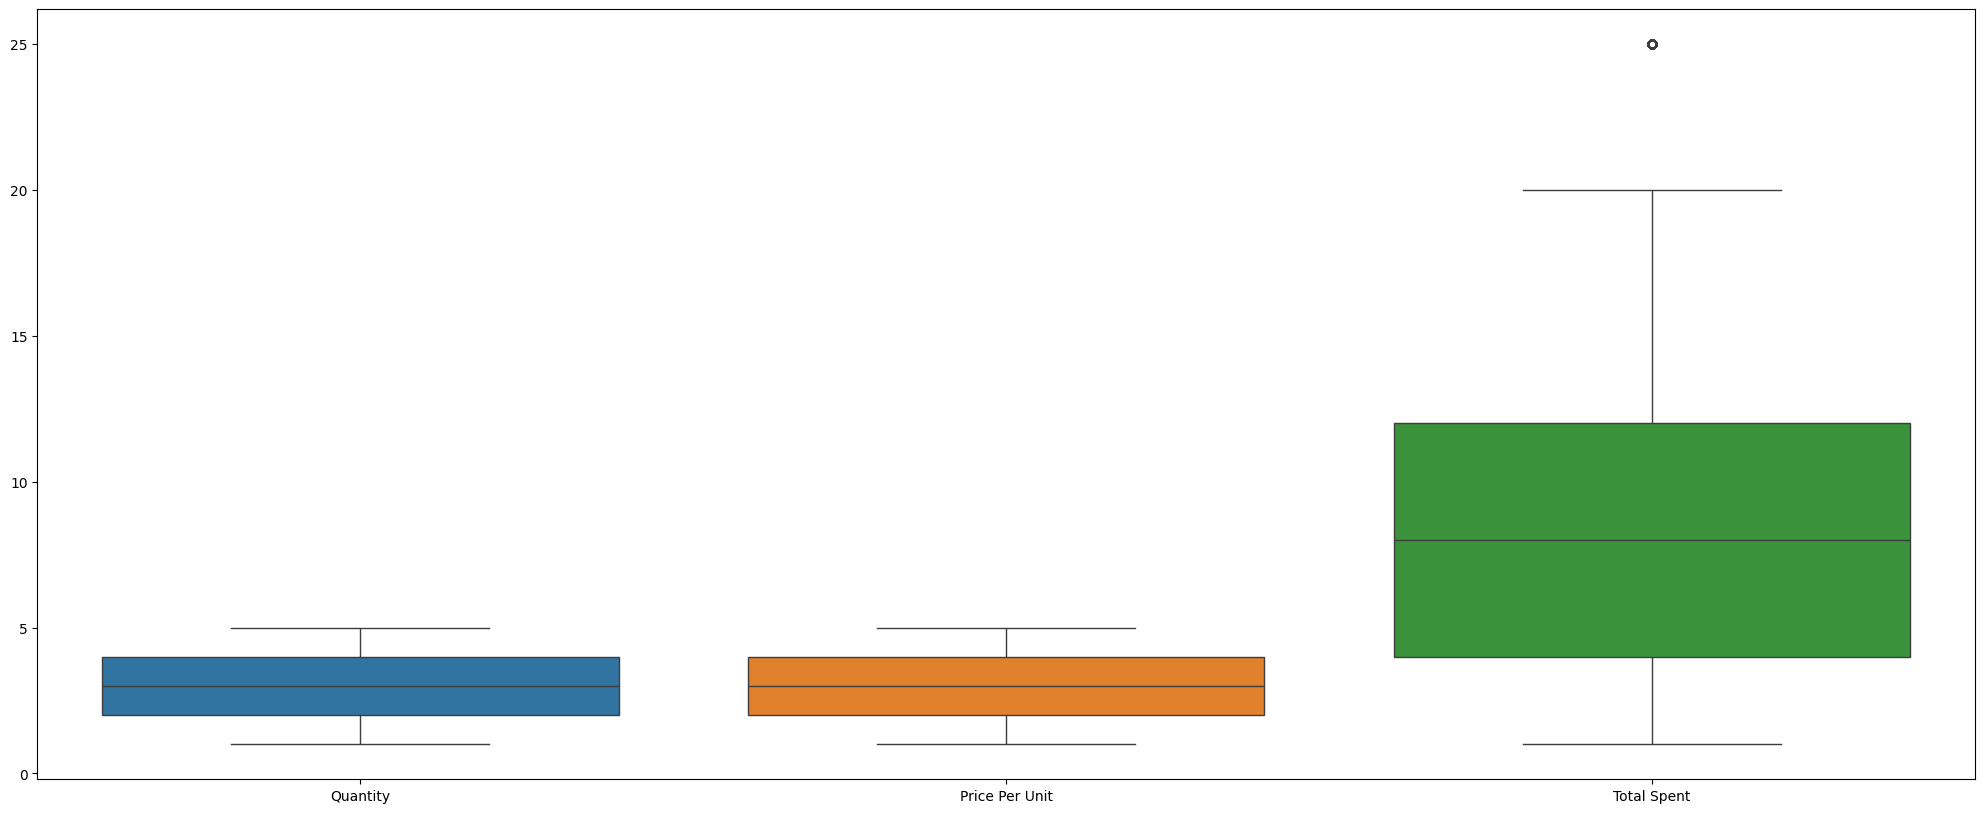

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(25,10))
sns.boxplot(df)
plt.show()

In [57]:
# Only 'Total Spent' has outliers
Q1 = df['Total Spent'].quantile(0.25)
Q3 = df['Total Spent'].quantile(0.75)
IQR = Q3 - Q1
low = Q1 - (1.5 * IQR)
high = Q3 + (1.5 * IQR)
df = df[(df['Total Spent'] >= low) & (df['Total Spent'] <= high)]

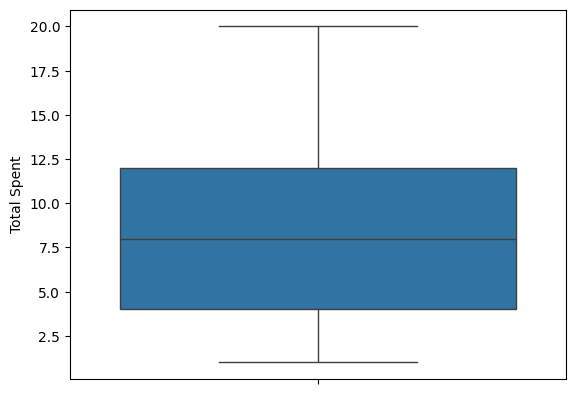

In [58]:
sns.boxplot(df['Total Spent'])
plt.show()

In [59]:
df.duplicated().sum()






np.int64(0)

In [60]:
df.describe()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,4425,4425,4425.0,4425.0,4425.0,4425,4425,4425
unique,4425,10,5.0,6.0,16.0,5,4,367
top,TXN_6170729,Juice,3.0,3.0,6.0,Digital Wallet,Takeaway,ERROR
freq,1,569,995.0,1302.0,464.0,1411,1987,67


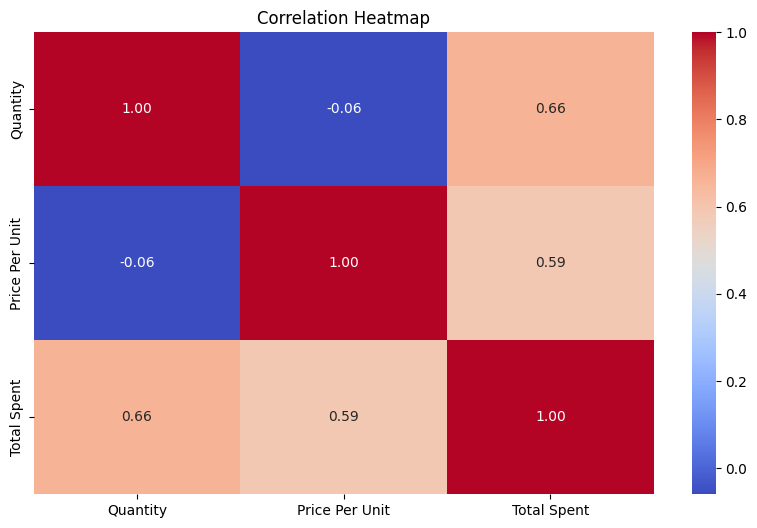

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure columns are numeric
for col in ['Quantity', 'Price Per Unit', 'Total Spent']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

plt.figure(figsize=(10, 6))
# Select numerical columns and plot correlation heatmap
sns.heatmap(df.select_dtypes('number').corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

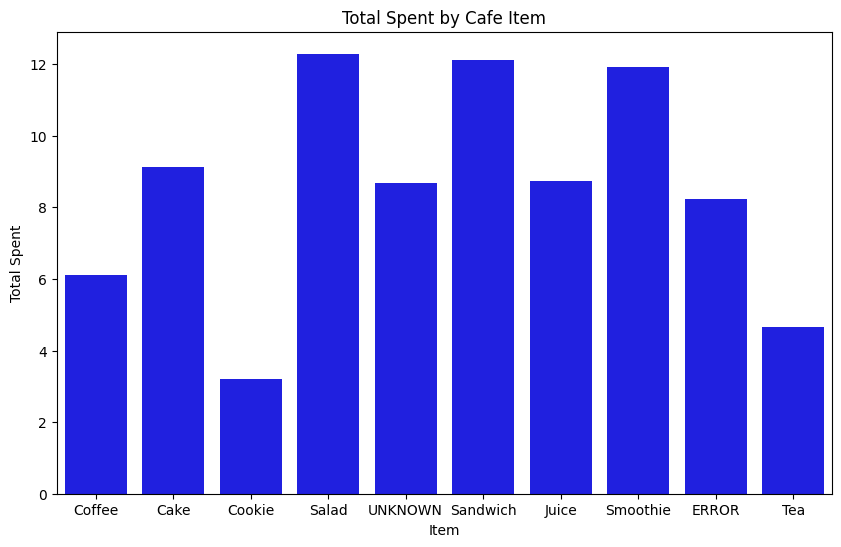

In [62]:
# Plotting Total Spent by Item type from the Cafe Sales dataset
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x=df['Item'], y=df['Total Spent'], color='blue', errorbar=None)
plt.title('Total Spent by Cafe Item')
plt.xlabel('Item')
plt.ylabel('Total Spent')
plt.show()

In [63]:
df.select_dtypes('object').head(1)

,Transaction ID,Item,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,Credit Card,Takeaway,2023-09-08


In [64]:
df.select_dtypes('object').head(3)

,Transaction ID,Item,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,Credit Card,In-store,2023-07-19


In [65]:
# One-Hot Encode appropriate categorical columns from the Cafe Sales dataset
OHE_Col = ['Item', 'Payment Method', 'Location']
df = pd.get_dummies(df, columns=OHE_Col, dtype=int)

In [66]:
import pandas as pd

# 1. Reload the original dirty dataset
try:
    df = pd.read_csv(path + '/dirty_cafe_sales.csv')
except:
    import kagglehub
    path = kagglehub.dataset_download("ahmedmohamed2003/cafe-sales-dirty-data-for-cleaning-training")
    df = pd.read_csv(path + '/dirty_cafe_sales.csv')

# 2. Convert and clean numerical columns
for col in ['Quantity', 'Price Per Unit', 'Total Spent']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[col] = df[col].fillna(df[col].median())

# 3. Fill missing categorical values with mode
for col in ['Item', 'Payment Method', 'Location']:
    df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else 'Unknown')

# 4. Safely perform One-Hot Encoding
OHE_Col = ['Item', 'Payment Method', 'Location']
df = pd.get_dummies(df, columns=OHE_Col, dtype=int)

# Preview the first few rows of the encoded dataset
df.head()

,Transaction ID,Quantity,Price Per Unit,Total Spent,Transaction Date,Item_Cake,Item_Coffee,Item_Cookie,Item_ERROR,Item_Juice,...,Item_UNKNOWN,Payment Method_Cash,Payment Method_Credit Card,Payment Method_Digital Wallet,Payment Method_ERROR,Payment Method_UNKNOWN,Location_ERROR,Location_In-store,Location_Takeaway,Location_UNKNOWN
0,TXN_1961373,2.0,2.0,4.0,2023-09-08,0,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
1,TXN_4977031,4.0,3.0,12.0,2023-05-16,1,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
2,TXN_4271903,4.0,1.0,8.0,2023-07-19,0,0,1,0,0,...,0,0,1,0,0,0,0,1,0,0
3,TXN_7034554,2.0,5.0,10.0,2023-04-27,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1
4,TXN_3160411,2.0,2.0,4.0,2023-06-11,0,1,0,0,0,...,0,0,0,1,0,0,0,1,0,0


In [67]:
df.select_dtypes('object').head(3)

,Transaction ID,Transaction Date
0,TXN_1961373,2023-09-08
1,TXN_4977031,2023-05-16
2,TXN_4271903,2023-07-19


In [68]:
# Show unique values of an actual column in our dataset
df['Transaction Date'].unique()

array(['2023-09-08', '2023-05-16', '2023-07-19', '2023-04-27',
       '2023-06-11', '2023-03-31', '2023-10-06', '2023-10-28',
       '2023-07-28', '2023-12-31', '2023-11-07', 'ERROR', '2023-05-03',
       '2023-06-01', '2023-03-21', '2023-11-15', '2023-06-10',
       '2023-02-24', '2023-03-25', '2023-01-15', '2023-04-04',
       '2023-03-30', '2023-12-01', '2023-09-18', '2023-06-03',
       '2023-12-13', '2023-04-20', '2023-04-10', '2023-03-11',
       '2023-06-02', '2023-11-06', '2023-08-15', '2023-10-09',
       '2023-05-28', '2023-07-17', '2023-04-29', '2023-06-08',
       '2023-06-29', '2023-04-17', '2023-12-22', '2023-01-10',
       '2023-10-02', '2023-02-23', '2023-03-22', '2023-11-03',
       '2023-03-02', '2023-06-26', '2023-05-02', '2023-09-05',
       '2023-01-08', '2023-03-15', '2023-11-25', '2023-12-05',
       '2023-03-19', '2023-06-27', '2023-04-19', '2023-10-07',
       '2023-09-30', '2023-05-27', '2023-11-18', '2023-10-20',
       '2023-10-03', '2023-10-27', '2023-04-06

In [69]:
# For encoding the date we will distribute the 'Transaction Date' into separate columns (day, month, year, quarter, day of week)
# 1. Convert to datetime, coercing errors like 'ERROR' and 'UNKNOWN' to NaT
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'], errors='coerce')

# 2. Fill missing or coerced dates (NaT) with the most frequent date (mode)
mode_date = df['Transaction Date'].mode()[0]
df['Transaction Date'] = df['Transaction Date'].fillna(mode_date)

# 3. Extract datetime features
df['day'] = df['Transaction Date'].dt.day
df['month'] = df['Transaction Date'].dt.month
df['year'] = df['Transaction Date'].dt.year
df['quarter'] = df['Transaction Date'].dt.quarter
df['day_of_week'] = df['Transaction Date'].dt.dayofweek

# 4. Drop the original Transaction Date column
df.drop(columns=['Transaction Date'], inplace=True)

df.head()

,Transaction ID,Quantity,Price Per Unit,Total Spent,Item_Cake,Item_Coffee,Item_Cookie,Item_ERROR,Item_Juice,Item_Salad,...,Payment Method_UNKNOWN,Location_ERROR,Location_In-store,Location_Takeaway,Location_UNKNOWN,day,month,year,quarter,day_of_week
0,TXN_1961373,2.0,2.0,4.0,0,1,0,0,0,0,...,0,0,0,1,0,8,9,2023,3,4
1,TXN_4977031,4.0,3.0,12.0,1,0,0,0,0,0,...,0,0,1,0,0,16,5,2023,2,1
2,TXN_4271903,4.0,1.0,8.0,0,0,1,0,0,0,...,0,0,1,0,0,19,7,2023,3,2
3,TXN_7034554,2.0,5.0,10.0,0,0,0,0,0,1,...,1,0,0,0,1,27,4,2023,2,3
4,TXN_3160411,2.0,2.0,4.0,0,1,0,0,0,0,...,0,0,1,0,0,11,6,2023,2,6


In [70]:
from sklearn.preprocessing import StandardScaler

# 1. Drop the unique identifier column that is not useful for modeling
if 'Transaction ID' in df.columns:
    df.drop(columns=['Transaction ID'], inplace=True)

# 2. Scale the numerical features
scaler = StandardScaler()
num_cols_to_scale = ['Quantity', 'Price Per Unit', 'Total Spent']
df[num_cols_to_scale] = scaler.fit_transform(df[num_cols_to_scale])

# View our fully prepared dataset
df.head()

,Quantity,Price Per Unit,Total Spent,Item_Cake,Item_Coffee,Item_Cookie,Item_ERROR,Item_Juice,Item_Salad,Item_Sandwich,...,Payment Method_UNKNOWN,Location_ERROR,Location_In-store,Location_Takeaway,Location_UNKNOWN,day,month,year,quarter,day_of_week
0,-0.741832,-0.765858,-0.832373,0,1,0,0,0,0,0,...,0,0,0,1,0,8,9,2023,3,4
1,0.702686,0.038066,0.532746,1,0,0,0,0,0,0,...,0,0,1,0,0,16,5,2023,2,1
2,0.702686,-1.569783,-0.149813,0,0,1,0,0,0,0,...,0,0,1,0,0,19,7,2023,3,2
3,-0.741832,1.645914,0.191466,0,0,0,0,0,1,0,...,1,0,0,0,1,27,4,2023,2,3
4,-0.741832,-0.765858,-0.832373,0,1,0,0,0,0,0,...,0,0,1,0,0,11,6,2023,2,6


In [71]:
df.head(1)

,Quantity,Price Per Unit,Total Spent,Item_Cake,Item_Coffee,Item_Cookie,Item_ERROR,Item_Juice,Item_Salad,Item_Sandwich,...,Payment Method_UNKNOWN,Location_ERROR,Location_In-store,Location_Takeaway,Location_UNKNOWN,day,month,year,quarter,day_of_week
0,-0.741832,-0.765858,-0.832373,0,1,0,0,0,0,0,...,0,0,0,1,0,8,9,2023,3,4


In [72]:
df.shape

(10000, 27)

In [73]:
# First lets divide the data into X(features) and y(Output using 'Total Spent')
X = df.drop(columns=['Total Spent'], axis=1)
y = df['Total Spent']

In [74]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
scaled_X=sc.fit_transform(X)

In [75]:
scaled_X

array([[-0.74183201, -0.76585843, -0.35852587, ...,  0.        ,
         0.49331428,  0.547087  ],
       [ 0.70268559,  0.03806581,  2.78919903, ...,  0.        ,
        -0.38509434, -0.91246035],
       [ 0.70268559, -1.56978268, -0.35852587, ...,  0.        ,
         0.49331428, -0.42594457],
       ...,
       [ 0.70268559, -0.76585843, -0.35852587, ...,  0.        ,
        -1.26350296,  0.06057122],
       [-0.01957321,  0.03806581, -0.35852587, ...,  0.        ,
         1.3717229 ,  1.03360279],
       [-0.01957321,  0.84199006, -0.35852587, ...,  0.        ,
         1.3717229 , -0.91246035]])

In [76]:
try:
  df.to_csv('dirty_cafe_sales.csv')
except ValueError:
  print("Enter correct value")
else:
  print("File saved successfully")


File saved successfully
